# Dự đoán mức thu nhập — ACS PUMS Texas 2024

Chuẩn bị dữ liệu, so sánh hai phiên bản đặc trưng A/B với CART và Random Forest. Chạy các cell theo thứ tự từ trên xuống.

Nguồn logic: ba file Python trên GitHub tại commit `34e0cf2e60fb`. Notebook độc lập, không import các file đó.

**Trước khi chạy:** đặt notebook tại thư mục gốc dự án; cần `folktables`, `numpy`, `pandas`, `scikit-learn`, dữ liệu Texas tại `data/pums/2024/1-Year/` và dictionary 2024. Huấn luyện đầy đủ có thể mất thời gian; Random Forest sử dụng các lõi CPU khả dụng.

## 1. Thư viện và thiết lập

In [1]:
import csv
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from folktables import ACSDataSource
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier

DICTIONARY_PATH = Path("data/pums/data_dict_2024/PUMS_Data_Dictionary_2024.csv")
DATA_DIR = Path("data/processed/texas_2024")
OUTPUT_DIR = Path("data/results/cart_randomforest_notebook")
RANDOM_STATE = 42
TEST_SIZE = 0.3
CV_FOLDS = 3
VARIANTS = ["A_detailed", "B_grouped"]
LABELS = [0, 1, 2]
plt.rcParams["figure.figsize"] = (9, 4)


In [2]:
BASE_FEATURES = [
    "AGEP",
    "SEX",
    "MAR",
    "ENG",
    "SCHL",
    "FOD1P",
    "COW",
    "WKWN",
    "WKHP",
    "OCCP",
    "INDP",
    "RAC1P",
    "CIT",
]

LABEL_NAMES = {
    0: "Low income",
    1: "Middle income",
    2: "High income",
}

FOD_GROUP_NAMES = {
    0: "No bachelor's degree",
    11: "Agriculture and related fields",
    13: "Environment and natural resources",
    14: "Architecture",
    15: "Area, ethnic, and civilization studies",
    19: "Communications and journalism",
    20: "Communications technologies",
    21: "Computer and information systems",
    22: "Personal and culinary services",
    23: "Education",
    24: "Engineering",
    25: "Engineering technologies",
    26: "Linguistics and foreign languages",
    29: "Family and consumer sciences",
    32: "Pre-law and legal studies",
    33: "English language and literature",
    34: "Liberal arts and humanities",
    35: "Library science",
    36: "Biological sciences",
    37: "Mathematics and statistics",
    38: "Military technologies",
    40: "Multi/interdisciplinary studies",
    41: "Parks, recreation, leisure, and fitness studies",
    48: "Philosophy and religious studies",
    49: "Theology and religious vocations",
    50: "Physical sciences",
    51: "Nuclear, industrial radiology, and biological technologies",
    52: "Psychology",
    53: "Criminal justice and fire protection",
    54: "Public administration, social services, and public policy",
    55: "Social sciences",
    56: "Construction services",
    57: "Electrical, mechanical, and precision technologies and production",
    59: "Transportation sciences and technologies",
    60: "Visual and performing arts",
    61: "Health professions and related programs",
    62: "Business",
    64: "History",
}


## 2. Nạp và chuẩn bị dữ liệu
Giữ 14 thuộc tính, lọc đối tượng nghiên cứu và xử lý giá trị không áp dụng ở ENG, FOD1P.

In [3]:
# 1. Nạp dữ liệu ACS PUMS 2024 của Texas
data_source = ACSDataSource(
    survey_year="2024",
    horizon="1-Year",
    survey="person",
    root_dir="data/pums",
)

df = data_source.get_data(states=["TX"], download=False)
print(f"Đã nạp dữ liệu: {df.shape[0]:,} dòng, {df.shape[1]} cột.")


Đã nạp dữ liệu: 292,272 dòng, 286 cột.


In [4]:
# 2. Chọn 14 thuộc tính nghiên cứu
STUDY_FEATURES = [
    "AGEP", "SEX", "MAR", "ENG", "SCHL", "FOD1P", "COW", "WKWN", "WKHP", "OCCP", "INDP", "RAC1P", "CIT", "PERNP",
]
df = df[STUDY_FEATURES].copy()
print(f"Kích thước sau khi chọn thuộc tính: {df.shape}")
df.head()


Kích thước sau khi chọn thuộc tính: (292272, 14)


,AGEP,SEX,MAR,ENG,SCHL,FOD1P,COW,WKWN,WKHP,OCCP,INDP,RAC1P,CIT,PERNP
0,43,2,5,NaN,17.0,NaN,1.0,16.0,40.0,310.0,8680.0,2,1,5300.0
1,46,1,3,1.0,18.0,NaN,1.0,NaN,NaN,4251.0,7770.0,1,1,0.0
2,19,2,5,1.0,19.0,NaN,2.0,NaN,NaN,4600.0,8561.0,1,5,0.0
3,83,1,2,NaN,21.0,6206.0,NaN,NaN,NaN,NaN,NaN,1,1,0.0
4,37,1,3,NaN,21.0,4901.0,NaN,NaN,NaN,NaN,NaN,9,1,0.0


In [6]:
# 3. Lọc nhóm đối tượng nghiên cứu
initial_rows = len(df)

df = df.loc[
    (df["AGEP"] >= 18)
    & (df["WKHP"] > 0)
    & (df["PERNP"] > 0)
    & (df["COW"] != 8)
].copy().reset_index(drop=True)

print(f"Số dòng sau khi lọc: {len(df):,}")
print(f"Số dòng bị loại: {initial_rows - len(df):,}")


Số dòng sau khi lọc: 146,275
Số dòng bị loại: 145,997


In [ ]:
# 4. Kiểm tra dữ liệu nhiễu
# Mã danh mục đối chiếu với ACS PUMS Data Dictionary 2024.
# Mã khuyết không tính là vi phạm.
CODE_COLUMNS = [
    "SEX", "MAR", "ENG", "SCHL", "FOD1P",
    "COW", "OCCP", "INDP", "RAC1P", "CIT",
]

valid_codes = {column: set() for column in CODE_COLUMNS}

with open(DICTIONARY_PATH, encoding="utf-8-sig", newline="") as file:
    for row in csv.reader(file):
        if len(row) >= 7 and row[0] == "VAL" and row[1] in valid_codes:
            if row[4].isdigit() and row[4] == row[5]:
                valid_codes[row[1]].add(int(row[4]))


# Miền giá trị của các biến số
numeric_ranges = {
    "AGEP": (0, 99),
    "WKWN": (1, 52),
    "WKHP": (1, 99),  # 99 nghĩa là 99 giờ trở lên
    "PERNP": (-10000, 1999998),
}


# Kiểm tra mã ngoài danh mục và giá trị ngoài miền
results = []

for column in CODE_COLUMNS:
    invalid = df[column].notna() & ~df[column].isin(valid_codes[column])

    results.append({
        "Biến": column,
        "Mã ngoài danh mục": sorted(df.loc[invalid, column].astype(str).unique()),
        "Số bản ghi vi phạm": invalid.sum(),
    })


for column, (low, high) in numeric_ranges.items():
    values = pd.to_numeric(df[column], errors="raise")

    invalid = values.notna() & (
        (values < low) | (values > high) | (values % 1 != 0)
    )

    results.append({
        "Biến": column,
        "Mã ngoài danh mục": sorted(df.loc[invalid, column].astype(str).unique()),
        "Số bản ghi vi phạm": invalid.sum(),
    })


display(pd.DataFrame(results))

In [ ]:
# 5. Xử lý giá trị khuyết thiếu
df["ENG"] = df["ENG"].fillna(0)
df["FOD1P"] = df["FOD1P"].fillna(0)

print("Đã xử lý giá trị khuyết thiếu ở ENG và FOD1P.")


Đã xử lý giá trị khuyết thiếu ở ENG và FOD1P.


In [8]:
# 5. Thống kê mô tả cơ bản
print("\nThông tin tập dữ liệu:")
df.info()

print("\nThống kê mô tả:")
display(df[["AGEP", "WKWN", "WKHP", "PERNP"]].describe())



Thông tin tập dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 146275 entries, 0 to 146274
Data columns (total 14 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   AGEP    146275 non-null  int64  
 1   SEX     146275 non-null  int64  
 2   MAR     146275 non-null  int64  
 3   ENG     146275 non-null  float64
 4   SCHL    146275 non-null  float64
 5   FOD1P   146275 non-null  float64
 6   COW     146275 non-null  float64
 7   WKWN    146275 non-null  float64
 8   WKHP    146275 non-null  float64
 9   OCCP    146275 non-null  float64
 10  INDP    146275 non-null  float64
 11  RAC1P   146275 non-null  int64  
 12  CIT     146275 non-null  int64  
 13  PERNP   146275 non-null  float64
dtypes: float64(9), int64(5)
memory usage: 15.6 MB

Thống kê mô tả:


,AGEP,WKWN,WKHP,PERNP
count,146275.000000,146275.000000,146275.000000,146275.000000
mean,43.535512,46.828569,39.137255,67431.825308
std,15.244025,12.347414,12.974837,84620.612665
min,18.000000,1.000000,1.000000,1.000000
25%,31.000000,52.000000,38.000000,21700.000000
50%,43.000000,52.000000,40.000000,45000.000000
75%,56.000000,52.000000,42.000000,80000.000000
max,92.000000,52.000000,99.000000,988000.000000


In [9]:
display(df.head())
missing = df[BASE_FEATURES + ["PERNP"]].isna().sum()
if missing.any():
    raise ValueError(f"Còn giá trị thiếu trước khi biến đổi:\n{missing[missing > 0]}")


,AGEP,SEX,MAR,ENG,SCHL,FOD1P,COW,WKWN,WKHP,OCCP,INDP,RAC1P,CIT,PERNP
0,43,2,5,0.0,17.0,0.0,1.0,16.0,40.0,310.0,8680.0,2,1,5300.0
1,36,2,5,0.0,22.0,3600.0,1.0,52.0,40.0,4640.0,7071.0,2,1,46500.0
2,24,2,5,0.0,21.0,2102.0,4.0,51.0,25.0,725.0,7870.0,1,1,10100.0
3,20,2,5,0.0,19.0,0.0,1.0,9.0,16.0,5400.0,7980.0,9,1,4000.0
4,31,1,3,0.0,17.0,0.0,1.0,52.0,60.0,6260.0,570.0,1,1,11000.0


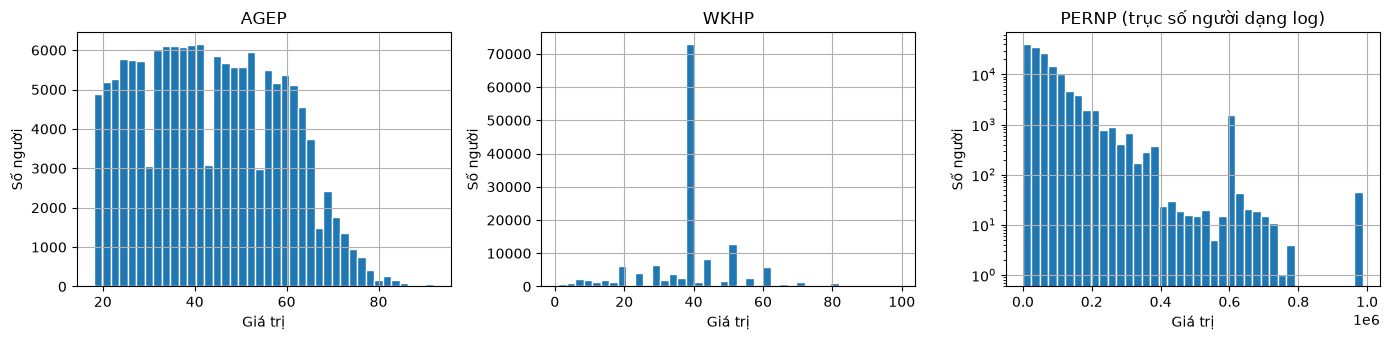

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for column, ax in zip(["AGEP", "WKHP", "PERNP"], axes):
    df[column].hist(bins=40, ax=ax, edgecolor="white")
    ax.set(title=column, xlabel="Giá trị", ylabel="Số người")
axes[2].set_yscale("log")
axes[2].set_title("PERNP (trục số người dạng log)")
plt.tight_layout()
plt.show()


### Phân tích dữ liệu sau tiền xử lý
Thống kê PERNP giúp xem mức thu nhập trong mẫu. Bảng và biểu đồ dưới đây so sánh thu nhập trung vị theo trình độ học vấn (SCHL). Trung vị ít bị ảnh hưởng bởi một số thu nhập rất cao hơn giá trị trung bình.

In [11]:
# Tra tên các mức học vấn từ từ điển dữ liệu
education_labels = {}
with open(DICTIONARY_PATH, encoding="utf-8-sig", newline="") as file:
    for row in csv.reader(file):
        if (
            len(row) >= 7
            and row[0] == "VAL"
            and row[1] == "SCHL"
            and row[4].isdigit()
            and row[4] == row[5]
        ):
            education_labels[int(row[4])] = row[6]

education_summary = (
    df.groupby("SCHL").agg(
        so_nguoi=("PERNP", "size"),
        thu_nhap_trung_vi=("PERNP", "median"),
    ).reset_index()
)
education_summary["Trình độ học vấn"] = (
    education_summary["SCHL"].astype(int).map(education_labels)
)
education_summary = education_summary.rename(
    columns={
        "so_nguoi": "Số người",
        "thu_nhap_trung_vi": "Thu nhập trung vị (USD/năm)",
    }
)

display(
    education_summary[
        [
            "SCHL",
            "Trình độ học vấn",
            "Số người",
            "Thu nhập trung vị (USD/năm)",
        ]
    ].sort_values("SCHL").round(0)
)


,SCHL,Trình độ học vấn,Số người,Thu nhập trung vị (USD/năm)
0,1.0,No schooling completed,2609,30000.0
1,2.0,"Nursery school, preschool",42,20000.0
2,3.0,Kindergarten,39,35000.0
3,4.0,Grade 1,44,29050.0
4,5.0,Grade 2,97,26100.0
5,6.0,Grade 3,247,26400.0
6,7.0,Grade 4,123,30000.0
7,8.0,Grade 5,263,28000.0
8,9.0,Grade 6,1276,28800.0
9,10.0,Grade 7,312,29800.0


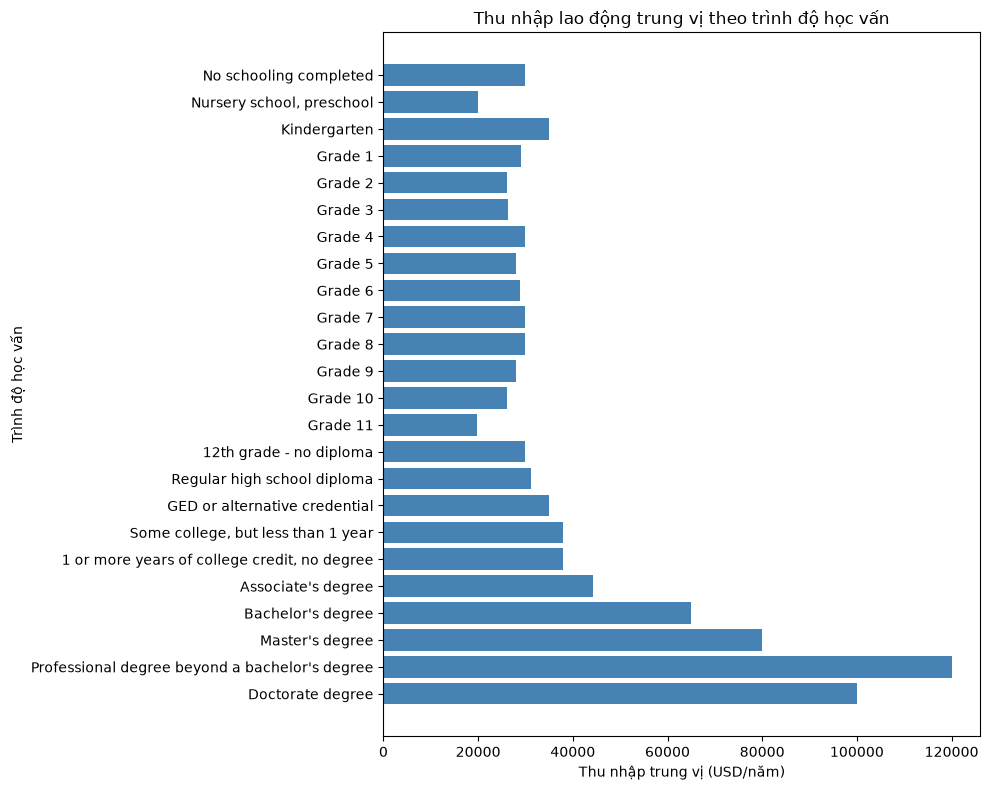

In [12]:
education_plot = education_summary.sort_values("SCHL")

plt.figure(figsize=(10, 8))
plt.barh(
    education_plot["Trình độ học vấn"],
    education_plot["Thu nhập trung vị (USD/năm)"],
    color="steelblue",
)
plt.gca().invert_yaxis()
plt.xlabel("Thu nhập trung vị (USD/năm)")
plt.ylabel("Trình độ học vấn")
plt.title("Thu nhập lao động trung vị theo trình độ học vấn")
plt.tight_layout()
plt.show()


## 3. Tạo bảng ánh xạ nhóm
A giữ mã chi tiết; B gộp OCCP, INDP và FOD1P theo dictionary. Mã vẫn được dùng dưới dạng số nguyên, không phải xử lý danh mục tự nhiên của cây.

In [13]:
entries = {
    "OCCP": [],
    "INDP": [],
    "FOD1P": [],
}

# Đọc mã thuộc tính từ Data Dictionary
with open(DICTIONARY_PATH, encoding="utf-8-sig", newline="") as file:
    for row in csv.reader(file):
        if len(row) < 7 or row[0] != "VAL" or row[1] not in entries:
            continue

        if not row[4].isdigit() or row[4] != row[5]:
            continue

        code = int(row[4])

        # Xác định nhóm của mã
        if row[1] == "FOD1P":
            group_key = code // 100
            group_label = FOD_GROUP_NAMES[group_key]

        elif code == 9920:
            group_key = "SPECIAL_9920"
            group_label = "Special code 9920"

        else:
            group_key = row[6].split("-")[0].strip()
            group_label = group_key

        entries[row[1]].append(
            (code, row[6], group_key, group_label)
        )


In [14]:
# Tạo bảng ánh xạ cho từng thuộc tính

mappings = {}

for column, records in entries.items():
    table = pd.DataFrame(
        records,
        columns=[
            "raw_code",
            "raw_label",
            "group_key",
            "group_label",
        ],
    )

    if column == "FOD1P":
        table.loc[len(table)] = [
            0,
            "N/A (less than bachelor's degree)",
            0,
            FOD_GROUP_NAMES[0],
        ]

        table["group_code"] = table["group_key"].astype(int)

    else:
        group_min_codes = table.groupby("group_key")["raw_code"].min()
        group_order = group_min_codes.sort_values().index

        group_codes = {}

        for number, key in enumerate(group_order, start=1):
            group_codes[key] = number

        table["group_code"] = (
            table["group_key"].map(group_codes).astype(int)
        )

    mappings[column] = table.sort_values("raw_code").reset_index(drop=True)


In [15]:
for column, table in mappings.items():
    print(f"{column}: {len(table)} mã, {table['group_code'].nunique()} nhóm")
    display(table.head())
    unknown = sorted(set(df[column].unique()) - set(table["raw_code"]))
    if unknown:
        raise ValueError(f"{column}: mã chưa có trong dictionary: {unknown}")


OCCP: 530 mã, 26 nhóm


,raw_code,raw_label,group_key,group_label,group_code
0,10,MGR-Chief Executives And Legislators,MGR,MGR,1
1,20,MGR-General And Operations Managers,MGR,MGR,1
2,40,MGR-Advertising And Promotions Managers,MGR,MGR,1
3,51,MGR-Marketing Managers,MGR,MGR,1
4,52,MGR-Sales Managers,MGR,MGR,1


INDP: 265 mã, 19 nhóm


,raw_code,raw_label,group_key,group_label,group_code
0,170,AGR-Crop Production,AGR,AGR,1
1,180,AGR-Animal Production And Aquaculture,AGR,AGR,1
2,190,AGR-Forestry Except Logging,AGR,AGR,1
3,270,AGR-Logging,AGR,AGR,1
4,280,"AGR-Fishing, Hunting And Trapping",AGR,AGR,1


FOD1P: 175 mã, 38 nhóm


,raw_code,raw_label,group_key,group_label,group_code
0,0,N/A (less than bachelor's degree),0,No bachelor's degree,0
1,1100,General Agriculture,11,Agriculture and related fields,11
2,1101,Agriculture Production And Management,11,Agriculture and related fields,11
3,1102,Agricultural Economics,11,Agriculture and related fields,11
4,1103,Animal Sciences,11,Agriculture and related fields,11


## 4. Chia train/test, tạo nhãn và biến đổi A/B
Chia 70/30 trước khi tính hai ngưỡng thu nhập trên train. Dùng cùng ngưỡng, cùng vị trí chia cho cả A và B. ANNUAL_HOURS là ước tính WKHP × WKWN.

In [16]:
data = df[BASE_FEATURES + ["PERNP"]].apply(
    pd.to_numeric,
    errors="raise",
).reset_index(drop=True)


In [17]:
# 3. Chia dữ liệu thành tập train và test
train_rows, test_rows = train_test_split(
    np.arange(len(data)),
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
)


In [18]:
# 4. Tính ngưỡng thu nhập từ tập train
q1 = data["PERNP"].iloc[train_rows].quantile(1 / 3)
q2 = data["PERNP"].iloc[train_rows].quantile(2 / 3)


In [19]:
# 5. Phân loại thu nhập thành ba nhóm
labels = pd.Series(
    np.select(
        [
            data["PERNP"] <= q1,
            data["PERNP"] <= q2,
        ],
        [0, 1],
        default=2,
    ),
    index=data.index,
    name="INCOME_CLASS",
)


In [20]:
# 6. Phiên bản A: giữ nguyên mã thuộc tính chi tiết
detailed = data[BASE_FEATURES].astype("int64").copy()

# Ước tính tổng số giờ làm việc trong năm
# WKHP = 99 biểu thị 99 giờ hoặc nhiều hơn mỗi tuần
detailed["ANNUAL_HOURS"] = detailed["WKHP"] * detailed["WKWN"]


In [21]:
# 7. Phiên bản B: thay mã chi tiết bằng mã nhóm
grouped = detailed.copy()

for column, table in mappings.items():
    group_codes = table.set_index("raw_code")["group_code"]

    grouped = grouped.rename(columns={column: f"{column}_GROUP"})
    grouped[f"{column}_GROUP"] = (
        data[column].map(group_codes).astype("int64")
    )


In [22]:
# 8. Trả về dữ liệu và thông tin cần thiết
prepared = {
    "variants": {
        "A_detailed": detailed,
        "B_grouped": grouped,
    },
    "labels": labels,
    "train_rows": train_rows,
    "test_rows": test_rows,
    "thresholds": (float(q1), float(q2)),
    "mappings": mappings,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
}


In [23]:
print(f"Ngưỡng train: q1 = {q1:,.2f}; q2 = {q2:,.2f}")
display(pd.DataFrame({
    "train": labels.iloc[train_rows].value_counts().reindex(LABELS, fill_value=0),
    "test": labels.iloc[test_rows].value_counts().reindex(LABELS, fill_value=0),
}).rename(index=LABEL_NAMES))
display(detailed.head())
display(grouped.head())


Ngưỡng train: q1 = 30,000.00; q2 = 66,000.00


,train,test
INCOME_CLASS,,
Low income,36268,15722
Middle income,32035,13679
High income,34089,14482


,AGEP,SEX,MAR,ENG,SCHL,FOD1P,COW,WKWN,WKHP,OCCP,INDP,RAC1P,CIT,ANNUAL_HOURS
0,43,2,5,0,17,0,1,16,40,310,8680,2,1,640
1,36,2,5,0,22,3600,1,52,40,4640,7071,2,1,2080
2,24,2,5,0,21,2102,4,51,25,725,7870,1,1,1275
3,20,2,5,0,19,0,1,9,16,5400,7980,9,1,144
4,31,1,3,0,17,0,1,52,60,6260,570,1,1,3120


,AGEP,SEX,MAR,ENG,SCHL,FOD1P_GROUP,COW,WKWN,WKHP,OCCP_GROUP,INDP_GROUP,RAC1P,CIT,ANNUAL_HOURS
0,43,2,5,0,17,0,1,16,40,1,15,2,1,640
1,36,2,5,0,22,36,1,52,40,16,10,2,1,2080
2,24,2,5,0,21,21,4,51,25,2,12,1,1,1275
3,20,2,5,0,19,0,1,9,16,18,13,9,1,144
4,31,1,3,0,17,0,1,52,60,20,3,1,1,3120


## 5. Lưu dữ liệu đã chuẩn bị
Xuất cùng định dạng CSV và metadata với bản Python. Phần huấn luyện bên dưới dùng trực tiếp dữ liệu trong bộ nhớ, không đọc lại CSV.

In [24]:
output = DATA_DIR
output.mkdir(parents=True, exist_ok=True)

labels = prepared["labels"]

positions = {
    "train": prepared["train_rows"],
    "test": prepared["test_rows"],
}


In [25]:
# 1. Tạo thông tin chung
metadata = {
    "survey_year": "2024",
    "state": "TX",
    "rows": len(labels),
    "random_state": prepared["random_state"],
    "test_size": prepared["test_size"],
    "split_method": "random shuffle before fitting tertiles; no stratification",
    "thresholds_train_only": {
        "q1": prepared["thresholds"][0],
        "q2": prepared["thresholds"][1],
    },
    "label_names": LABEL_NAMES,
    "label_rule": "0: PERNP <= q1; 1: q1 < PERNP <= q2; 2: PERNP > q2",
    "annual_hours": "WKHP * WKWN (estimate; WKHP 99 means 99 or more)",
    "encoding": "integer codes; no native nominal handling, one-hot or target encoding",
    "variants": {},
    "splits": {},
}


In [26]:
# 2. Lưu nhãn train/test và thống kê số lượng từng lớp
for split, indices in positions.items():
    labels.iloc[indices].to_csv(
        output / f"y_{split}.csv",
        index=False,
    )

    counts = labels.iloc[indices].value_counts().reindex(
        [0, 1, 2],
        fill_value=0,
    )

    class_counts = {}

    for label, count in counts.items():
        class_counts[int(label)] = int(count)

    metadata["splits"][split] = {
        "rows": len(indices),
        "class_counts": class_counts,
    }


In [27]:
# 3. Lưu hai phiên bản dữ liệu A và B
for variant, features in prepared["variants"].items():
    metadata["variants"][variant] = {
        "features": features.columns.tolist(),
    }

    for split, indices in positions.items():
        features.iloc[indices].to_csv(
            output / f"X_{variant}_{split}.csv",
            index=False,
        )


In [28]:
# 4. Lưu các bảng ánh xạ
for column, table in prepared["mappings"].items():
    table.to_csv(
        output / f"mapping_{column}.csv",
        index=False,
        encoding="utf-8-sig",
    )


In [29]:
# 5. Lưu metadata
with open(output / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

print(f"Đã xuất dữ liệu: {output}")


Đã xuất dữ liệu: data\processed\texas_2024


## 6. Huấn luyện và đánh giá
Dùng Stratified K-Fold 3 folds và GridSearchCV để chọn siêu tham số theo Macro-F1 trên train. Đánh giá trên test sau khi chọn tham số. Giữ vòng lặp cho bốn tổ hợp để tránh lặp code.

Kết quả notebook được lưu riêng tại `data/results/cart_randomforest_notebook/`, không ghi đè kết quả hiện có.

In [30]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
y_train = labels.iloc[train_rows]
y_test = labels.iloc[test_rows]
target_names = [LABEL_NAMES[label] for label in LABELS]
summaries = []
evaluations = {}


In [31]:
# 3. Huấn luyện và đánh giá các mô hình
for version in VARIANTS:

    print(f"\n========== Phiên bản {version} ==========")

    # Đọc dữ liệu tương ứng với phiên bản A hoặc B
    x_train = prepared["variants"][version].iloc[train_rows]
    x_test = prepared["variants"][version].iloc[test_rows]

    for model_name in ["CART", "RandomForest"]:

        print(f"\n[{version} / {model_name}] Đang huấn luyện...", flush=True)

        # 3.1. Khởi tạo mô hình và lưới siêu tham số
        if model_name == "CART":
            model = DecisionTreeClassifier(
                criterion="gini",
                random_state=RANDOM_STATE,
            )

            params = {
                "max_depth": [12, None],
                "min_samples_leaf": [20, 100],
            }

        else:
            model = RandomForestClassifier(
                criterion="gini",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )

            params = {
                "n_estimators": [100, 200],
                "max_features": ["sqrt"],
                "min_samples_leaf": [5, 20],
            }

        # 3.2. Thiết lập Stratified K-Fold
        folds = StratifiedKFold(
            n_splits=CV_FOLDS,
            shuffle=True,
            random_state=RANDOM_STATE,
        )

        # 3.3. Tìm siêu tham số tốt nhất
        search = GridSearchCV(
            model,
            params,
            scoring="f1_macro",
            cv=folds,
            n_jobs=1,
        )

        search.fit(x_train, y_train)

        best_model = search.best_estimator_
        prediction = best_model.predict(x_test)

        # 3.4. Đánh giá mô hình
        report = classification_report(
            y_test,
            prediction,
            labels=LABELS,
            target_names=target_names,
            output_dict=True,
            zero_division=0,
        )

        prefix = OUTPUT_DIR / f"{version}_{model_name}"

        # Lưu Classification Report
        pd.DataFrame(report).T.to_csv(
            f"{prefix}_classification_report.csv",
            encoding="utf-8-sig",
        )

        # Lưu Confusion Matrix
        pd.DataFrame(
            confusion_matrix(y_test, prediction, labels=LABELS),
            index=target_names,
            columns=target_names,
        ).rename_axis("True label").to_csv(
            f"{prefix}_confusion_matrix.csv",
            encoding="utf-8-sig",
        )

        # Lưu Feature Importance
        pd.DataFrame({
            "feature": x_train.columns,
            "importance": best_model.feature_importances_,
        }).sort_values(
            "importance",
            ascending=False,
        ).to_csv(
            f"{prefix}_feature_importances.csv",
            index=False,
            encoding="utf-8-sig",
        )

        evaluations[(version, model_name)] = {
            "report": pd.DataFrame(report).T,
            "matrix": confusion_matrix(y_test, prediction, labels=LABELS),
            "importance": pd.Series(best_model.feature_importances_, index=x_train.columns),
        }

        # 3.5. Lưu kết quả tổng hợp
        summaries.append({
            "variant": version,
            "model": model_name,
            "cv_macro_f1": search.best_score_,
            "test_accuracy": accuracy_score(y_test, prediction),
            "test_macro_f1": report["macro avg"]["f1-score"],
            "test_macro_precision": report["macro avg"]["precision"],
            "test_macro_recall": report["macro avg"]["recall"],
            "best_params": json.dumps(
                search.best_params_,
                ensure_ascii=False,
            ),
        })

        print(
            f"CV Macro-F1 = {search.best_score_:.4f} | "
            f"Test Macro-F1 = {report['macro avg']['f1-score']:.4f}",
            flush=True,
        )



========== Phiên bản A_detailed ==========

[A_detailed / CART] Đang huấn luyện...
CV Macro-F1 = 0.6739 | Test Macro-F1 = 0.6738

[A_detailed / RandomForest] Đang huấn luyện...
CV Macro-F1 = 0.6955 | Test Macro-F1 = 0.6982

========== Phiên bản B_grouped ==========

[B_grouped / CART] Đang huấn luyện...
CV Macro-F1 = 0.6716 | Test Macro-F1 = 0.6707

[B_grouped / RandomForest] Đang huấn luyện...
CV Macro-F1 = 0.6909 | Test Macro-F1 = 0.6927


## 7. So sánh kết quả
Xếp hạng theo CV Macro-F1, không dùng điểm test để chọn mô hình. Feature importance là độ quan trọng dựa trên giảm độ hỗn tạp, không phải kết luận nhân quả.

In [32]:
# 4. So sánh và xếp hạng mô hình
comparison = pd.DataFrame(summaries).sort_values(
    "cv_macro_f1",
    ascending=False,
)

comparison.to_csv(
    OUTPUT_DIR / "comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nSo sánh các mô hình:")
print(comparison.to_string(index=False))

best = comparison.iloc[0]

print(
    f"\nMô hình được ưu tiên theo CV: "
    f"{best['variant']} / {best['model']}"
)

print(f"Đã lưu kết quả tại: {OUTPUT_DIR}")



So sánh các mô hình:
   variant        model  cv_macro_f1  test_accuracy  test_macro_f1  test_macro_precision  test_macro_recall                                                          best_params
A_detailed RandomForest     0.695527       0.701479       0.698193              0.699102           0.698001 {"max_features": "sqrt", "min_samples_leaf": 5, "n_estimators": 100}
 B_grouped RandomForest     0.690891       0.695919       0.692684              0.693695           0.692401 {"max_features": "sqrt", "min_samples_leaf": 5, "n_estimators": 100}
A_detailed         CART     0.673902       0.679306       0.673813              0.673518           0.674614                         {"max_depth": null, "min_samples_leaf": 100}
 B_grouped         CART     0.671626       0.675250       0.670651              0.670955           0.670923                         {"max_depth": null, "min_samples_leaf": 100}

Mô hình được ưu tiên theo CV: A_detailed / RandomForest
Đã lưu kết quả tại: data\results\car

In [33]:
display(comparison.reset_index(drop=True).round(4))


,variant,model,cv_macro_f1,test_accuracy,test_macro_f1,test_macro_precision,test_macro_recall,best_params
0,A_detailed,RandomForest,0.6955,0.7015,0.6982,0.6991,0.6980,"{""max_features"": ""sqrt"", ""min_samples_leaf"": 5..."
1,B_grouped,RandomForest,0.6909,0.6959,0.6927,0.6937,0.6924,"{""max_features"": ""sqrt"", ""min_samples_leaf"": 5..."
2,A_detailed,CART,0.6739,0.6793,0.6738,0.6735,0.6746,"{""max_depth"": null, ""min_samples_leaf"": 100}"
3,B_grouped,CART,0.6716,0.6753,0.6707,0.6710,0.6709,"{""max_depth"": null, ""min_samples_leaf"": 100}"


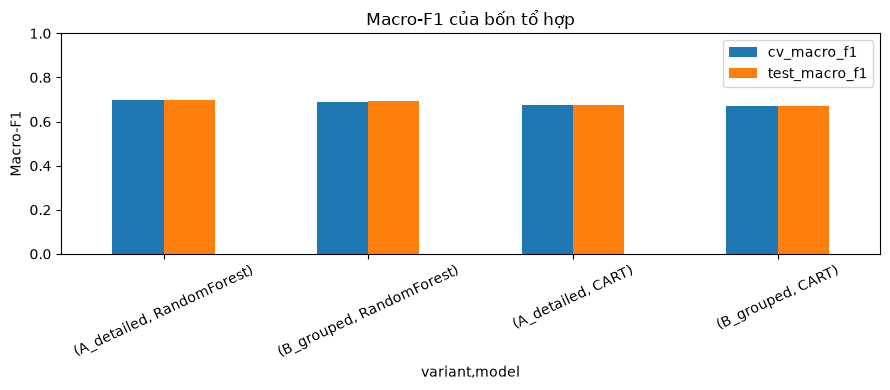

In [34]:
comparison.set_index(["variant", "model"])[["cv_macro_f1", "test_macro_f1"]].plot.bar(
    ylim=(0, 1), rot=25, title="Macro-F1 của bốn tổ hợp", ylabel="Macro-F1"
)
plt.tight_layout()
plt.show()


## 8. Xem chi tiết kết quả
Ma trận nhầm lẫn, chỉ số từng lớp và các đặc trưng quan trọng của từng tổ hợp.

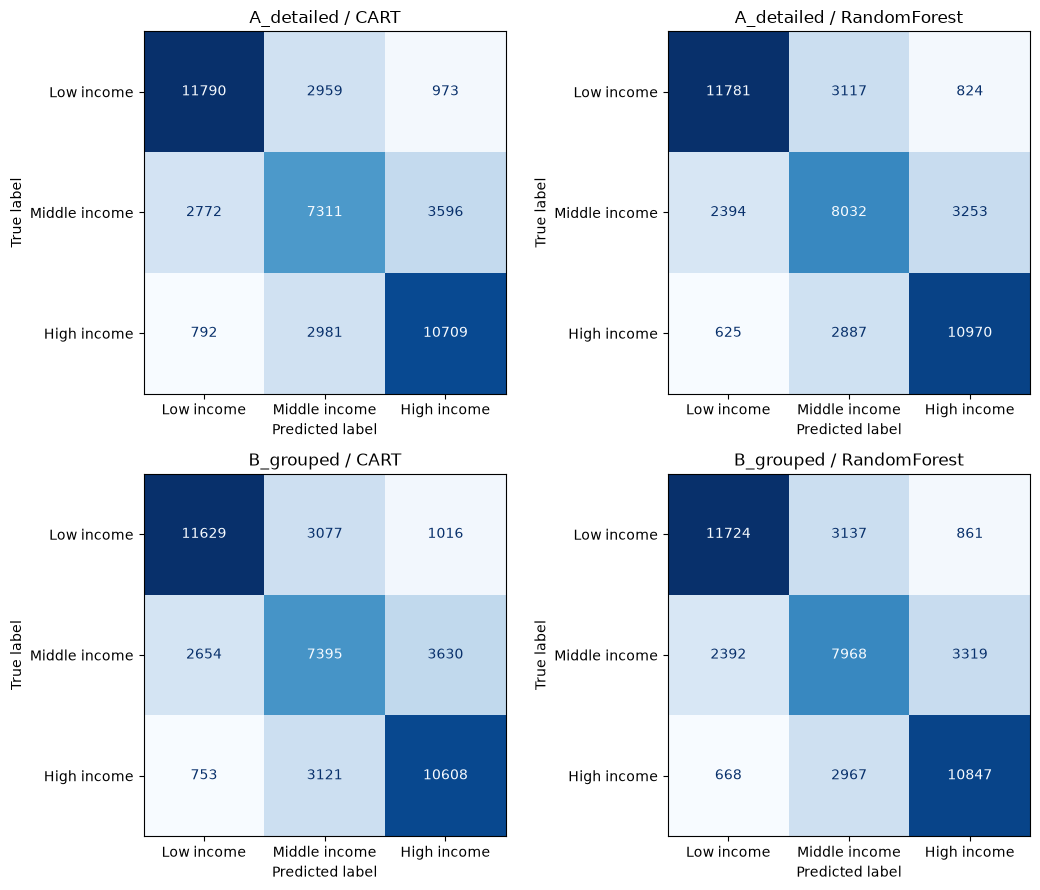

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ((version, model_name), result), ax in zip(evaluations.items(), axes.flat):
    ConfusionMatrixDisplay(result["matrix"], display_labels=target_names).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set(title=f"{version} / {model_name}", xlabel="Predicted label", ylabel="True label")
plt.tight_layout()
plt.show()


In [36]:
for (version, model_name), result in evaluations.items():
    print(f"{version} / {model_name}")
    display(result["report"].round(4))


A_detailed / CART


,precision,recall,f1-score,support
Low income,0.7679,0.7499,0.7588,15722.0000
Middle income,0.5517,0.5345,0.5430,13679.0000
High income,0.7009,0.7395,0.7197,14482.0000
accuracy,0.6793,0.6793,0.6793,0.6793
macro avg,0.6735,0.6746,0.6738,43883.0000
weighted avg,0.6784,0.6793,0.6786,43883.0000


A_detailed / RandomForest


,precision,recall,f1-score,support
Low income,0.7960,0.7493,0.7720,15722.0000
Middle income,0.5722,0.5872,0.5796,13679.0000
High income,0.7290,0.7575,0.7430,14482.0000
accuracy,0.7015,0.7015,0.7015,0.7015
macro avg,0.6991,0.6980,0.6982,43883.0000
weighted avg,0.7042,0.7015,0.7024,43883.0000


B_grouped / CART


,precision,recall,f1-score,support
Low income,0.7734,0.7397,0.7562,15722.0000
Middle income,0.5440,0.5406,0.5423,13679.0000
High income,0.6954,0.7325,0.7135,14482.0000
accuracy,0.6753,0.6753,0.6753,0.6753
macro avg,0.6710,0.6709,0.6707,43883.0000
weighted avg,0.6762,0.6753,0.6754,43883.0000


B_grouped / RandomForest


,precision,recall,f1-score,support
Low income,0.7930,0.7457,0.7686,15722.0000
Middle income,0.5662,0.5825,0.5742,13679.0000
High income,0.7218,0.7490,0.7352,14482.0000
accuracy,0.6959,0.6959,0.6959,0.6959
macro avg,0.6937,0.6924,0.6927,43883.0000
weighted avg,0.6988,0.6959,0.6970,43883.0000


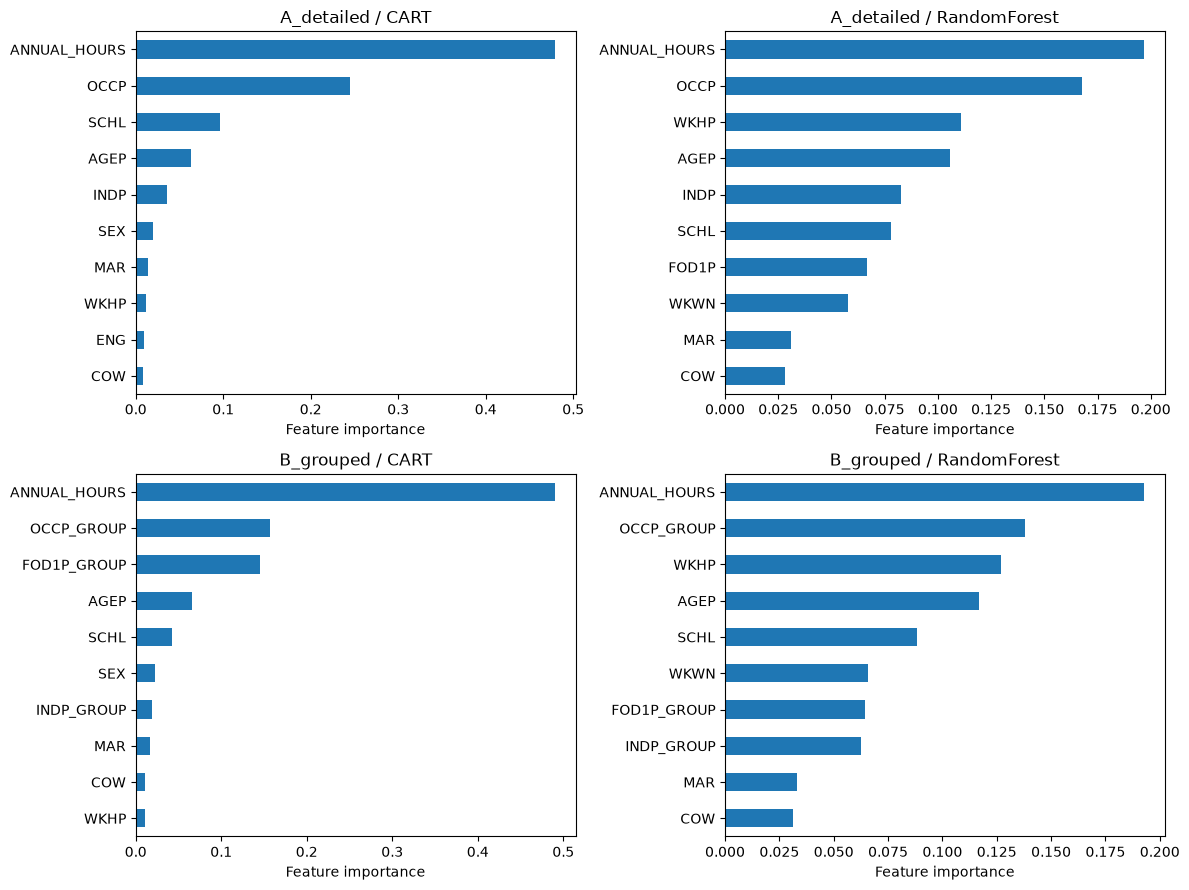

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ((version, model_name), result), ax in zip(evaluations.items(), axes.flat):
    result["importance"].nlargest(10).sort_values().plot.barh(ax=ax)
    ax.set(title=f"{version} / {model_name}", xlabel="Feature importance")
plt.tight_layout()
plt.show()
